В нашем распоряжении два csv-файла: измерения для белого и красного вин соответственно.
Объединим эти данные в один датасет и добавим столбец определения вида вина:

**is_red**:
* 0 - вино белое;
* 1 - вино красное;

In [24]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    "/Users/xololibra/Desktop/ml_course_mai/regression/data/wine+quality/"
)

red_wine = pd.read_csv(data_dir / "winequality-red.csv", sep=";")
white_wine = pd.read_csv(data_dir / "winequality-white.csv", sep=";")

red_wine["is_red"] = 1
white_wine["is_red"] = 0

df = pd.concat([red_wine, white_wine], ignore_index=True)

Попробуем сформировать первичные представления о целевой переменной:

In [25]:
print(df["quality"].describe())

count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64


Видим, что наблюдаемые оценки лежат в диапозоне от 3 до 9, среднее значение близко к 6, примерно половина выборки лежит в диапазоне между 5 и 6.
Я говорю примерно, потому что в датасете присутствуют повторяющиеся значения (у разных объектов могут повторяться значения quality).


Оценим кол-во повторов:

In [26]:
print("Полные повторы строк:", df.duplicated().sum())

Полные повторы строк: 1177


Разделим данные на два класса: первый будет использоваться для обучения (80%), второй - для тестов (20%). При этом учтем повторяющиеся строки, ибо
1177 из 6497 - это более 18%. Если этого не сделать, то копии одного и того же примера могут оказаться и в train, и в test, что может привести к более оптимистичной оценке качества модели.

Я выбрал стандартное соотношение train/test, так как на текущем этапе мне важнее больше примеров для выявления закономерностей, иначе я не пойму, как выстроить веса модели.

In [27]:
from sklearn.model_selection import GroupShuffleSplit

X = df.drop(columns="quality")
y = df["quality"]

# Одинаковые значения всех признаков - одна группа.
groups = X.groupby(
    list(X.columns),
    sort=False,
    dropna=False,
).ngroup()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()  # Матрица признаков (train dataset).
X_test = X.iloc[test_idx].copy()  # Матрица признаков (test dataset).

y_train = y.iloc[train_idx].copy()  # Вектор ответов (train dataset).
y_test = y.iloc[test_idx].copy()  # Вектор ответов (test dataset).

print(X_train.shape, X_test.shape)

(5210, 12) (1287, 12)


Теперь я хочу узнать, какое качество предсказаний можно получить с помощью самого простого правила - даем всем винам одинаковую оценку, вне зависимости от ксилотности и прочих признаков.

В качестве такой оценки (константы) я решил выбрать среднее качество вин в train dataset:

In [28]:
print(y_train.mean())  # baseline_value (константа).

5.814011516314779


Теперь любому образцу вина буду предсказывать качество **5.814**.

In [29]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)  # Вычисляем и запоминаем среднее y_train.

pred_base = baseline.predict(
    X_test)  # По сути порождаем массив [5.814, 5.814, ...], который потом сопоставляется с настоящей оценкой в каждом объекте.

baseline_rmse = root_mean_squared_error(y_test, pred_base)
baseline_mae = mean_absolute_error(y_test, pred_base)

print(f"Baseline RMSE: {baseline_rmse:.3f}")
print(f"Baseline MAE: {baseline_mae:.3f}")

Baseline RMSE: 0.852
Baseline MAE: 0.679


Благодаря этим метрикам мы можем охарактеризовать качество постоянного предсказания. Поэтому при построении моделей, учитывающих характеристики вин, мы наглядно сможем продемонстрировать важность (или неважность) учитывания этих самиых характеристик в общем.

Вновь посмотрим на значения целевой переменной:

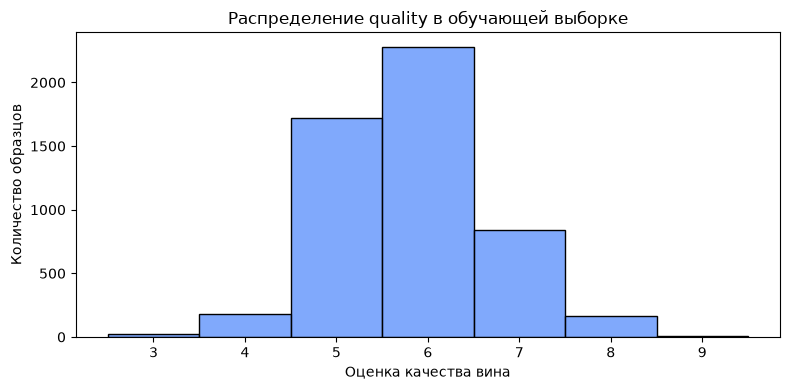

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.histplot(x=y_train, discrete=True)  # Мне интересны распределения вокруг целых значений.

plt.xticks(sorted(y_train.unique()))
plt.xlabel("Оценка качества вина")
plt.ylabel("Количество образцов")
plt.title("Распределение quality в обучающей выборке")

plt.tight_layout()
plt.show()

Такая концентрация ответов около среднего объясняет, почему постоянное предсказание около 6 может давать сравнительно небольшую ошибку даже без использования признаков вина. Поэтому качество обученных моделей необходимо сопоставлять с baseline.
Для редких оценок у модели будет меньше обучающих примеров, поэтому можно ожидать, что их предсказание окажется сложнее.

Так как для решения нашей задачи мы бы хотели обучить линейную регрессию, было бы хорошо найти признаки, "наиболее линейно" связанные с целевой переменной, иначе говоря, посмотреть на коэффициент корреляции Пирсона между признаками и целевой переменной.

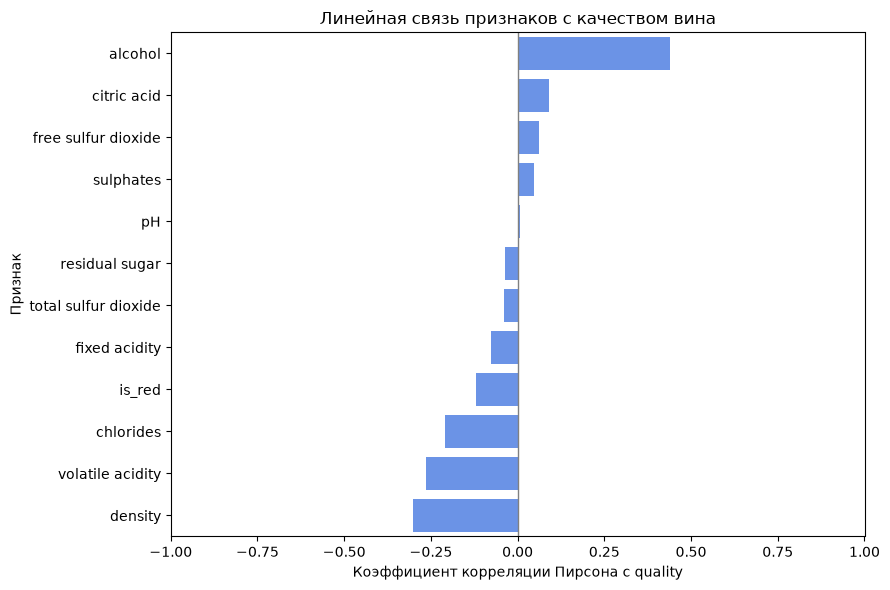

alcohol                 0.441
citric acid             0.092
free sulfur dioxide     0.060
sulphates               0.048
pH                      0.007
residual sugar         -0.037
total sulfur dioxide   -0.039
fixed acidity          -0.076
is_red                 -0.120
chlorides              -0.211
volatile acidity       -0.263
density                -0.302
dtype: float64


In [31]:
numeric_data = X_train.select_dtypes(include="number")

correlations = (
    numeric_data
    .corrwith(y_train, method="pearson")
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=correlations.to_numpy(),
    y=correlations.index,
)

plt.axvline(0, color="gray", linewidth=1)
plt.xlim(-1, 1)
plt.xlabel("Коэффициент корреляции Пирсона с quality")
plt.ylabel("Признак")
plt.title("Линейная связь признаков с качеством вина")

plt.tight_layout()
plt.show()

print(correlations.round(3))

Наибольшая по модулю корреляция Пирсона наблюдается у alcohol (~ 0.441): образцы с большим содержанием алкоголя в среднем имеют более высокие оценки.
Для density (~ -0.302) и volatile acidity (~ -0.263) наблюдается отрицательная связь: большим значениям плотности и летучей кислотности в среднем соответствуют меньшие оценки качества. Эти связи слабее, чем у alcohol.

Нарисуем графики зависимости целевой переменной от каждого из признаков:

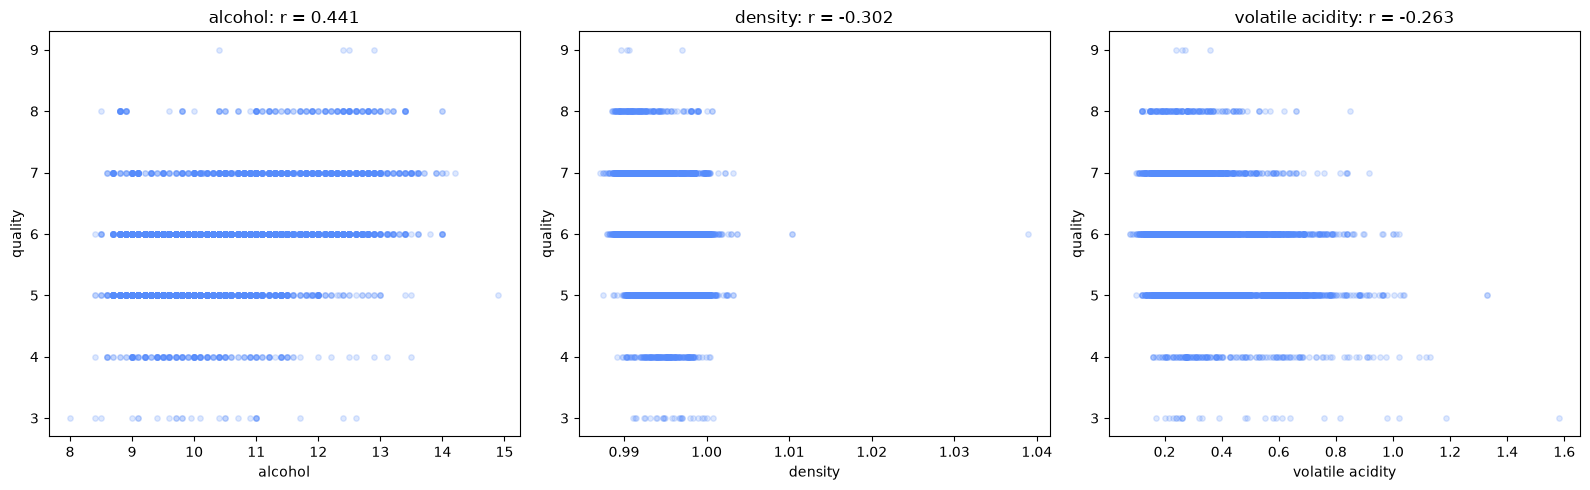

In [32]:
top_features = correlations.abs().nlargest(3).index

fig, axes = plt.subplots(ncols=3, figsize=(16, 5))

for ax, feature in zip(axes, top_features):
    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.2,
        s=15,
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("quality")
    ax.set_title(
        f"{feature}: r = {correlations[feature]:.3f}"
    )
    ax.set_yticks(sorted(y_train.unique()))

plt.tight_layout()
plt.show()

На диаграммах заметно существенное перекрытие значений признаков для разных оценок качества. Следовательно, ни один из этих признаков по отдельности не определяет качество однозначно.

# Линейная регрессия

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)

linear_model.fit(X_train, y_train)

pred_train = linear_model.predict(X_train)
pred_test = linear_model.predict(X_test)

print(
    "Train RMSE:",
    root_mean_squared_error(y_train, pred_train),
)
print(
    "Train MAE:",
    mean_absolute_error(y_train, pred_train),
)
print(
    "Test RMSE:",
    root_mean_squared_error(y_test, pred_test),
)
print(
    "Test MAE:",
    mean_absolute_error(y_test, pred_test),
)

Train RMSE: 0.7375219463106766
Train MAE: 0.5700202217734373
Test RMSE: 0.712148189381149
Test MAE: 0.5601093184207447


В условии ЛР сказано, сравнивать абсолютные значения коэффициентов признаков, измеренных в совершенно разных масштабах, напрямую может быть некорректно.
Я добавил StandardScaler, чтобы нивелировать это замечание. Признаки измеряются в разных масштабах: плотность близка к 1, содержание алкоголя — примерно к 10–11, концентрации других веществ могут иметь существенно большие значения. После преобразования обучающие значения имеют среднее около нуля и стандартное отклонение около единицы.
Также масштабирование необходимо для дальнейшей регуляризации, ибо без него признаки будут штрафоваться несоразмерно из-за разного масштаба.

Линейная регрессия превосходит постоянный baseline по обеим тестовым метрикам. Близкие значения обучающей и тестовой ошибок не указывают на выраженное переобучение при данном разбиении.

In [34]:
regressor = linear_model.named_steps["linearregression"]

coefficients = pd.Series(
    regressor.coef_,
    index=X_train.columns,
    name="coefficient",
)

print(
    coefficients
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .round(3)
)

print("Свободный член:", regressor.intercept_)

density                -0.284
residual sugar          0.281
alcohol                 0.277
volatile acidity       -0.244
is_red                  0.138
sulphates               0.116
fixed acidity           0.097
free sulfur dioxide     0.096
total sulfur dioxide   -0.095
pH                      0.068
chlorides              -0.030
citric acid            -0.007
Name: coefficient, dtype: float64
Свободный член: 5.8140115163147765


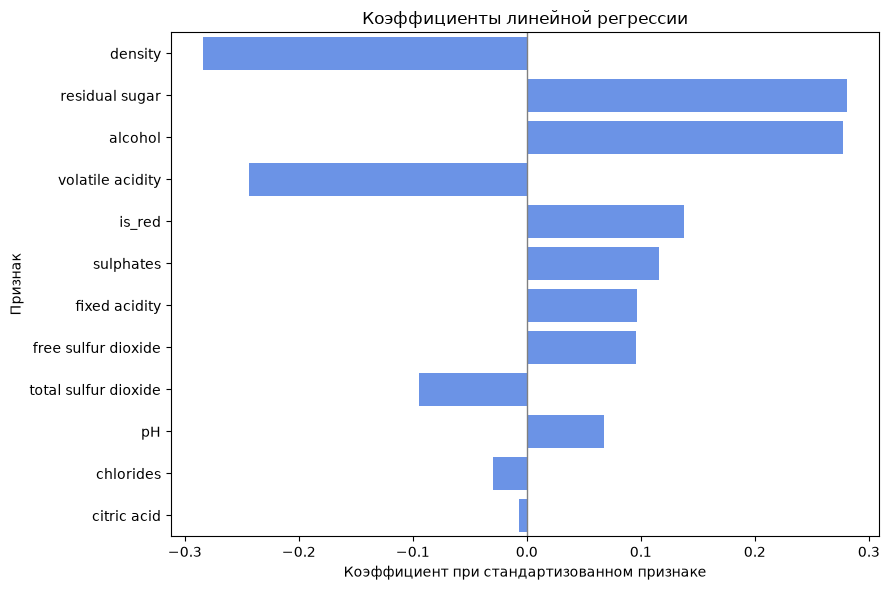

In [35]:
ordered = coefficients.sort_values(
    key=lambda values: values.abs(),
    ascending=False,
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=ordered.to_numpy(),
    y=ordered.index,
)

plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Коэффициент при стандартизованном признаке")
plt.ylabel("Признак")
plt.title("Коэффициенты линейной регрессии")

plt.tight_layout()
plt.show()

Откуда взялся сахар? Корреляция Пирсона рассматривала сахар и качество отдельно от остальных признаков. Коэффициент регрессии описывает изменение предсказания при изменении сахара с учётом остальных признаков. Поскольку признаки связаны между собой, результаты могут существенно различаться.
Следовательно, можно сделать вывод, что совместный анализ признаков дает дополнительную информацию по сравнению с парными корреляциями.

Попробуем использовать регуляризацию с целью прохождеия порога RMSE:

In [36]:
from sklearn.model_selection import GroupShuffleSplit

# Одинаковые строки должны оставаться в одной части.
groups_train = X_train.groupby(
    list(X_train.columns),
    sort=False,
    dropna=False,
).ngroup()

validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

fit_idx, val_idx = next(
    validation_splitter.split(X_train, y_train, groups=groups_train)
)

X_fit = X_train.iloc[fit_idx].copy()
y_fit = y_train.iloc[fit_idx].copy()

X_val = X_train.iloc[val_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Для обучения:", X_fit.shape)
print("Для валидации:", X_val.shape)

Для обучения: (4162, 12)
Для валидации: (1048, 12)


Выделим внутри train dataset одну валидационную часть.

In [37]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

candidates = {
    "LinearRegression": make_pipeline(
        StandardScaler(),
        LinearRegression(),
    )
}

for alpha in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    candidates[f"Ridge alpha={alpha}"] = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha),
    )

rows = []

for name, model in candidates.items():
    model.fit(X_fit, y_fit)

    pred_fit = model.predict(X_fit)
    pred_val = model.predict(X_val)

    rows.append({
        "model": name,
        "Train RMSE": root_mean_squared_error(y_fit, pred_fit),
        "Validation RMSE": root_mean_squared_error(y_val, pred_val),
        "Validation MAE": mean_absolute_error(y_val, pred_val),
    })

ridge_results = (
    pd.DataFrame(rows)
    .set_index("model")
    .sort_values("Validation RMSE")
)

display(ridge_results.round(5))

,Train RMSE,Validation RMSE,Validation MAE
model,,,
LinearRegression,0.74678,0.70160,0.55009
Ridge alpha=0.001,0.74678,0.70160,0.55009
Ridge alpha=0.01,0.74678,0.70160,0.55009
Ridge alpha=0.1,0.74678,0.70160,0.55009
Ridge alpha=1,0.74678,0.70161,0.55010
Ridge alpha=10,0.74679,0.70165,0.55019
Ridge alpha=100,0.74727,0.70191,0.55092
Ridge alpha=1000,0.75631,0.70756,0.55831


На выбранном валидационном разбиении Ridge с проверенными значениями параметра регуляризации не улучшила качество относительно обычной линейной регрессии. Минимальный RMSE составил около 0.70160

Линейную регрессию можно свести к полиномиальной модели. Я имею ввиду попытку описать нелинейные зависимости от исходных признаков. Проверим стеепень 2 на том же разбиении:

In [38]:
from sklearn.preprocessing import PolynomialFeatures

poly_candidates = {}
poly_rows = []

for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha),
    )

    model.fit(X_fit, y_fit)
    poly_candidates[alpha] = model

    pred_fit = model.predict(X_fit)
    pred_val = model.predict(X_val)

    poly_rows.append({
        "alpha": alpha,
        "Train RMSE": root_mean_squared_error(y_fit, pred_fit),
        "Validation RMSE": root_mean_squared_error(y_val, pred_val),
        "Validation MAE": mean_absolute_error(y_val, pred_val),
    })

poly_results = (
    pd.DataFrame(poly_rows)
    .set_index("alpha")
    .sort_values("Validation RMSE")
)

display(poly_results.round(5))

,Train RMSE,Validation RMSE,Validation MAE
alpha,,,
100.00,0.70787,0.67309,0.53809
10.00,0.70432,0.67447,0.53817
1.00,0.70392,0.67584,0.53807
0.10,0.70385,0.67657,0.53826
0.01,0.70385,0.67672,0.53830
1000.00,0.72524,0.67964,0.54300


Регуляризация теперь помогает: при alpha=100 обучающая ошибка выше, чем при слабом штрафе, зато валидационная ниже. Значит мы улучшили предсказание на данных вне обучения. Проведем финальное обучение линейной регрессии с полиномиальными признакам 2 степени и L2-регуляризацией:

In [39]:
best_alpha = poly_results["Validation RMSE"].idxmin()

final_linear_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=best_alpha),
)

# Валидационная часть снова участвует в обучении:
# настройки модели уже выбраны.
final_linear_model.fit(X_train, y_train)

pred_final_train = final_linear_model.predict(X_train)
pred_final_test = final_linear_model.predict(X_test)

print("Выбранный alpha:", best_alpha)

print(
    "Train RMSE:",
    root_mean_squared_error(y_train, pred_final_train),
)
print(
    "Train MAE:",
    mean_absolute_error(y_train, pred_final_train),
)
print(
    "Test RMSE:",
    root_mean_squared_error(y_test, pred_final_test),
)
print(
    "Test MAE:",
    mean_absolute_error(y_test, pred_final_test),
)

Выбранный alpha: 100.0
Train RMSE: 0.6985923429140419
Train MAE: 0.5456089673974507
Test RMSE: 0.690467183115977
Test MAE: 0.5390652516008081


Добавление полиномиальных признаков второй степени и L2-регуляризации позволило снизить тестовый RMSE с 0.7121 до 0.6905. Параметр регуляризации α = 100 выбран по отдельной валидационной выборке внутри обучающей части. Полученная модель удовлетворяет порогу RMSE < 0.7 на выделенном тесте.

# Случайный лес

Попробуем случайный лес. Он усредняет предсказания нескольких деревьев и может
учитывать нелинейные зависимости между признаками. Масштабировать данные не нужно.

Возьмем 300 деревьев и минимум 2 объекта в листе. Сначала проверим модель
на той же валидации, затем обучим на всей обучающей выборке.


In [40]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=300,  # Количество деревьев в лесу.
    min_samples_leaf=2,  # Минимум 2 обучающих объекта в каждом листе.
    max_features=0.8,  # При каждом разбиении рассматриваем случайные 80% признаков.
    random_state=42,  # Фиксируем случайность для воспроизводимости.
    n_jobs=-1,  # Используем все доступные ядра процессора.
)

forest_model.fit(X_fit, y_fit)
pred_forest_val = forest_model.predict(X_val)
forest_val_rmse = root_mean_squared_error(y_val, pred_forest_val)

print("Validation RMSE:", forest_val_rmse)

forest_model.fit(X_train, y_train)
pred_forest_train = forest_model.predict(X_train)
pred_forest_test = forest_model.predict(X_test)

print("Train RMSE:", root_mean_squared_error(y_train, pred_forest_train))
print("Train MAE:", mean_absolute_error(y_train, pred_forest_train))
print("Test RMSE:", root_mean_squared_error(y_test, pred_forest_test))
print("Test MAE:", mean_absolute_error(y_test, pred_forest_test))


Validation RMSE: 0.6701567230214993
Train RMSE: 0.2865694771904941
Train MAE: 0.1981616100896331
Test RMSE: 0.6529048646232317
Test MAE: 0.5056741797297353


Случайный лес получил тестовый RMSE около 0.653 и MAE около 0.506.
Это лучше baseline и обеих линейных моделей. При этом ошибка на обучении
значительно меньше тестовой: лес сильнее подстраивается под обучающие примеры.

# Градиентный бустинг

Теперь обучим градиентный бустинг. В отличие от леса, здесь деревья добавляются
последовательно: каждое следующее помогает исправить ошибки текущего ансамбля.
Используем 200 деревьев глубины 3. Данные и валидацию оставим прежними.


In [41]:
from sklearn.ensemble import GradientBoostingRegressor

boosting_model = GradientBoostingRegressor(
    n_estimators=200,  # Количество последовательно добавляемых деревьев.
    learning_rate=0.05,  # Умножаем поправку каждого нового дерева на 0.05.
    max_depth=3,  # Максимальная глубина каждого дерева.
    min_samples_leaf=5,  # Минимум 5 обучающих объектов в каждом листе.
    subsample=0.8,  # Каждое дерево обучаем на случайных 80% обучающих строк.
    random_state=42,  # Фиксируем случайность для воспроизводимости.
)

boosting_model.fit(X_fit, y_fit)
pred_boosting_val = boosting_model.predict(X_val)
boosting_val_rmse = root_mean_squared_error(y_val, pred_boosting_val)

print("Validation RMSE:", boosting_val_rmse)

boosting_model.fit(X_train, y_train)
pred_boosting_train = boosting_model.predict(X_train)
pred_boosting_test = boosting_model.predict(X_test)

print("Train RMSE:", root_mean_squared_error(y_train, pred_boosting_train))
print("Train MAE:", mean_absolute_error(y_train, pred_boosting_train))
print("Test RMSE:", root_mean_squared_error(y_test, pred_boosting_test))
print("Test MAE:", mean_absolute_error(y_test, pred_boosting_test))


Validation RMSE: 0.6717903625702429
Train RMSE: 0.6328143871286833
Train MAE: 0.4961698018660971
Test RMSE: 0.6722456948891206
Test MAE: 0.5221601693502902


Бустинг получил тестовый RMSE около 0.672 и MAE около 0.522.
Он тоже превзошел baseline и линейные модели, но уступил лесу.

# Сравнение моделей

Сведем результаты в одну таблицу. Все тестовые метрики посчитаны на одной выборке.
Модель для дальнейшего анализа выберем по валидационному RMSE.


In [49]:
validation_results = pd.Series({
    "Linear Regression": ridge_results.loc["LinearRegression", "Validation RMSE"],
    "Linear Regression + полиномиальные признаки + L2": poly_results.loc[best_alpha, "Validation RMSE"],
    "Random Forest": forest_val_rmse,
    "Gradient Boosting": boosting_val_rmse,
}, name="Validation RMSE")

display(validation_results.sort_values().round(4))
best_name = validation_results.idxmin()
print("Выбрана модель:", best_name)

predictions = {
    "Baseline": pred_base,
    "Linear Regression": pred_test,
    "Linear Regression + полиномиальные признаки + L2": pred_final_test,
    "Random Forest": pred_forest_test,
    "Gradient Boosting": pred_boosting_test,
}

results = pd.DataFrame([
    {
        "Модель": name,
        "RMSE": root_mean_squared_error(y_test, prediction),
        "MAE": mean_absolute_error(y_test, prediction),
    }
    for name, prediction in predictions.items()
]).set_index("Модель")

display(results.round(4))


Random Forest                                       0.6702
Gradient Boosting                                   0.6718
Linear Regression + полиномиальные признаки + L2    0.6731
Linear Regression                                   0.7016
Name: Validation RMSE, dtype: float64

Выбрана модель: Random Forest


,RMSE,MAE
Модель,,
Baseline,0.8524,0.6795
Linear Regression,0.7121,0.5601
Linear Regression + полиномиальные признаки + L2,0.6905,0.5391
Random Forest,0.6529,0.5057
Gradient Boosting,0.6722,0.5222


Все обученные модели превзошли baseline. Среднее значение, которое использует
baseline, минимизирует RMSE среди постоянных прогнозов, но не учитывает признаки.
Обычная линейная регрессия учитывает их линейный вклад, полиномиальная - также
квадраты и взаимодействия.

Минимальный RMSE и на валидации, и на тесте получил случайный лес. Его и будем
анализировать дальше. Небольшой разрыв между моделями на одной валидации еще
не гарантирует такого же порядка на новых данных.

MAE показывает среднюю абсолютную ошибку в баллах quality. RMSE тоже выражен
в баллах, но сильнее реагирует на крупные ошибки из-за их возведения в квадрат.
Поэтому отдельные большие промахи увеличивают RMSE сильнее, чем MAE.

# Важность признаков

Посмотрим, какие признаки чаще помогали деревьям уменьшать ошибку при разбиениях.


,Random Forest,Gradient Boosting
alcohol,0.2404,0.4158
volatile acidity,0.1295,0.1806
free sulfur dioxide,0.0881,0.1009
density,0.0824,0.0309
sulphates,0.0772,0.0716
total sulfur dioxide,0.0695,0.0420
residual sugar,0.0662,0.0468
pH,0.0649,0.0310
chlorides,0.0627,0.0258
citric acid,0.0597,0.0290


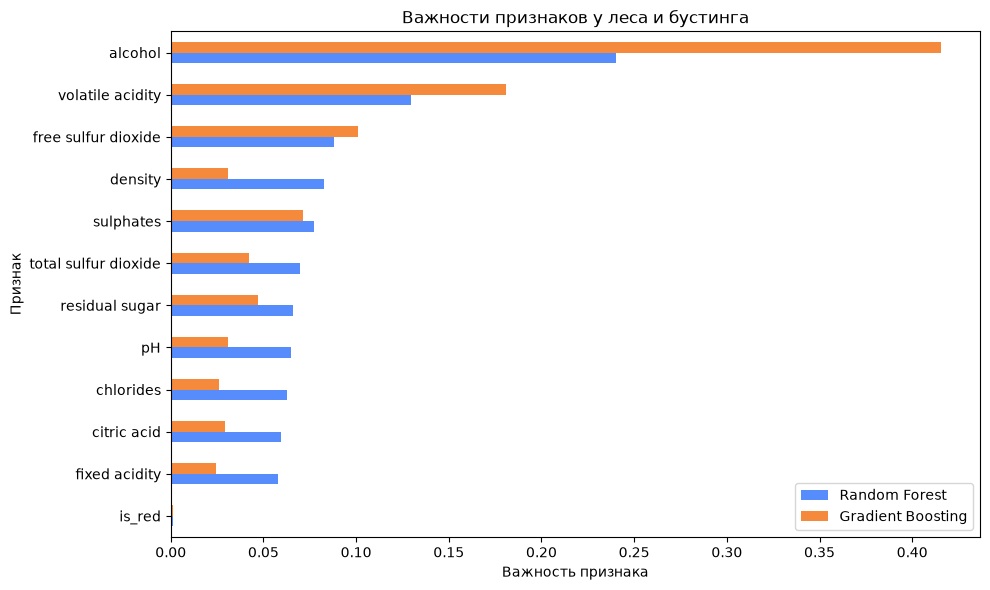

In [43]:
importances = pd.DataFrame({
    "Random Forest": forest_model.feature_importances_,
    "Gradient Boosting": boosting_model.feature_importances_,
}, index=X_train.columns)

importances = importances.sort_values("Random Forest", ascending=False)
display(importances.round(4))

importances.iloc[::-1].plot.barh(figsize=(10, 6))
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важности признаков у леса и бустинга")
plt.tight_layout()
plt.show()


У обеих моделей первые три места заняли alcohol, volatile acidity и free sulfur
dioxide. Первые два признака выделялись и по корреляции Пирсона. В обычной линейной регрессии выделялись density, residual sugar и alcohol:
разные модели описывают зависимости по-разному, поэтому рейтинги не совпадают полностью.

Важность не показывает направление связи. Связанные признаки могут заменять друг
друга, а признаки с большим числом возможных порогов могут получать преимущество.
Поэтому нельзя считать этот рейтинг универсальным.

Причинный вывод тоже сделать нельзя: высокая важность alcohol не означает,
что добавление спирта улучшит качество вина. Мы видим связи в наблюдаемых данных,
на которые могут влиять другие характеристики и условия производства.

# Анализ ошибок

Посмотрим на ошибки выбранного по валидации леса. Положительная ошибка означает
завышение оценки, отрицательная - занижение. Прогнозы не округляем.


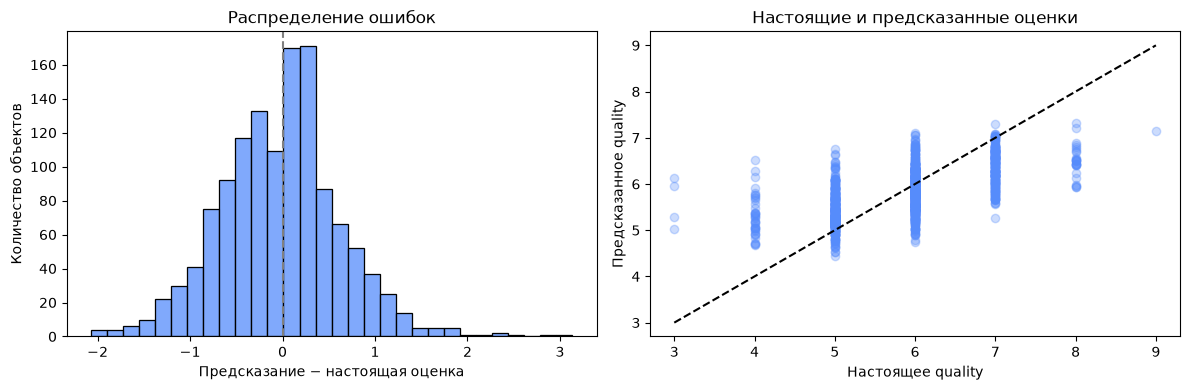

In [44]:
errors = pd.DataFrame({
    "quality": y_test,
    "prediction": predictions[best_name],
})
errors["error"] = errors["prediction"] - errors["quality"]
errors["abs_error"] = errors["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=errors, x="error", bins=30, ax=axes[0])
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set_xlabel("Предсказание − настоящая оценка")
axes[0].set_ylabel("Количество объектов")
axes[0].set_title("Распределение ошибок")

axes[1].scatter(errors["quality"], errors["prediction"], alpha=0.3)
axes[1].plot([3, 9], [3, 9], "k--")
axes[1].set_xlabel("Настоящее quality")
axes[1].set_ylabel("Предсказанное quality")
axes[1].set_title("Настоящие и предсказанные оценки")

plt.tight_layout()
plt.show()


Большинство ошибок сосредоточено около нуля, но есть отдельные крупные промахи.
На втором графике видно, что низкие оценки часто завышаются, а высокие - занижаются.
Проверим это отдельно для каждого значения quality.


,count,mean_prediction,MAE,RMSE,train_count
quality,,,,,
3,4,5.5987,2.5987,2.6388,26
4,39,5.3146,1.3146,1.3853,177
5,419,5.4109,0.4448,0.5582,1719
6,556,5.8702,0.3690,0.4536,2280
7,241,6.3614,0.6447,0.7453,838
8,27,6.5027,1.4973,1.5360,166
9,1,7.1532,1.8468,1.8468,4


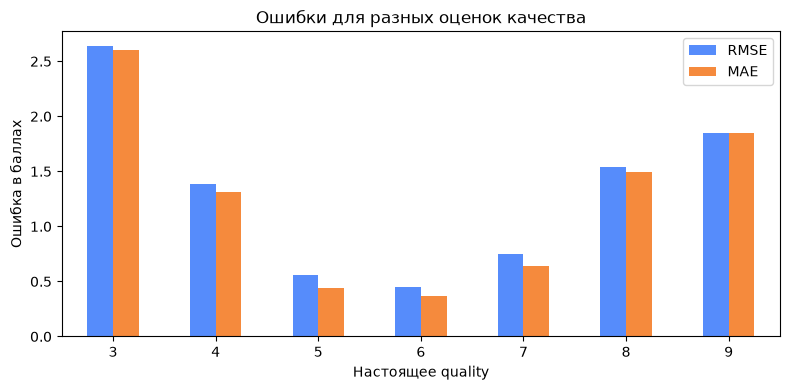

In [45]:
errors["squared_error"] = errors["error"] ** 2

errors_by_quality = errors.groupby("quality").agg(
    count=("error", "size"),
    mean_prediction=("prediction", "mean"),
    MAE=("abs_error", "mean"),
    MSE=("squared_error", "mean"),
)
errors_by_quality["RMSE"] = errors_by_quality.pop("MSE") ** 0.5
errors_by_quality["train_count"] = y_train.value_counts()
display(errors_by_quality.round(4))

errors_by_quality[["RMSE", "MAE"]].plot.bar(figsize=(8, 4), rot=0)
plt.xlabel("Настоящее quality")
plt.ylabel("Ошибка в баллах")
plt.title("Ошибки для разных оценок качества")
plt.tight_layout()
plt.show()


Лучше всего модель справляется с частыми оценками 5–6. Для quality=3 средний
прогноз около 5.6, для quality=8 — около 6.5: крайние оценки смещаются к центру.
Таких примеров в обучении мало, а химические характеристики разных оценок
перекрываются. При неоднозначности модель склонна предсказывать ближе к среднему.
Для quality=9 в test всего один объект, поэтому метрика этой группы нестабильна.

Теперь посмотрим на объекты с самыми большими ошибками.


In [46]:
worst_errors = errors.nlargest(5, "abs_error")
worst_errors = worst_errors.join(
    X_test[["is_red", "alcohol", "density", "volatile acidity", "residual sugar"]]
)

display(worst_errors.round(4))


,quality,prediction,error,abs_error,squared_error,is_red,alcohol,density,volatile acidity,residual sugar
5008,3,6.1353,3.1353,3.1353,9.8302,0,11.0,0.9916,0.23,0.7
2044,3,5.9514,2.9514,2.9514,8.7109,0,11.5,0.9937,0.32,11.0
5335,4,6.5095,2.5095,2.5095,6.2975,0,12.7,0.9914,0.32,8.0
2430,4,6.2812,2.2812,2.2812,5.2040,0,11.5,0.9935,0.17,5.5
832,3,5.2804,2.2804,2.2804,5.2001,1,9.9,0.9983,0.44,1.5


У строки 5008 настоящее quality=3, а прогноз около 6.14. При этом alcohol=11.0
и volatile acidity=0.23: по EDA такое сочетание может встречаться у более качественных
вин. Признаки не позволили распознать редкую низкую оценку.

У строки 2044 тоже quality=3, но прогноз около 5.95. Alcohol=11.5 сочетается
с volatile acidity=0.32: признаки дают неоднозначную картину. Возможно, на низкую
оценку повлияли свойства вина, которых нет среди входных измерений.

У строки 5335 quality=4, а прогноз около 6.51. Высокий alcohol=12.7 и низкая
density=0.99144 согласуются с тенденцией к более высоким оценкам. Это возможное
объяснение завышения, но не доказанная причина. Для оценок 3 и 4 в обучении
всего 26 и 177 примеров соответственно.

На локальном тесте лучший результат получил случайный лес: RMSE около 0.653,
MAE около 0.506. Линейная модель с полиномиальными признаками и Ridge тоже
прошла порог: RMSE около 0.690.
